<a href="https://colab.research.google.com/github/asmipandey18/Elevvo_Ml_Internship/blob/main/task4_loan_approval_prediction/Loan_approval_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [109]:
import pandas as pd

In [110]:
df = pd.read_csv("/content/loan_approval_dataset.csv")

In [111]:
df.shape

(4269, 13)

In [112]:
df.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


In [113]:
df.columns.tolist()

['loan_id',
 ' no_of_dependents',
 ' education',
 ' self_employed',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value',
 ' loan_status']

In [114]:
df.columns = df.columns.str.strip()
df = df.drop(columns=["loan_id"])
df.columns

Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_status'],
      dtype='object')

In [115]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   no_of_dependents          4269 non-null   int64 
 1   education                 4269 non-null   object
 2   self_employed             4269 non-null   object
 3   income_annum              4269 non-null   int64 
 4   loan_amount               4269 non-null   int64 
 5   loan_term                 4269 non-null   int64 
 6   cibil_score               4269 non-null   int64 
 7   residential_assets_value  4269 non-null   int64 
 8   commercial_assets_value   4269 non-null   int64 
 9   luxury_assets_value       4269 non-null   int64 
 10  bank_asset_value          4269 non-null   int64 
 11  loan_status               4269 non-null   object
dtypes: int64(9), object(3)
memory usage: 400.3+ KB


In [116]:
df.isnull().sum()

,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0
luxury_assets_value,0


In [117]:
df.duplicated().sum()

np.int64(0)

In [118]:
df["loan_status"].value_counts()

,count
loan_status,
Approved,2656
Rejected,1613


In [119]:
df["loan_status"].value_counts(normalize=True).round(3)

,proportion
loan_status,
Approved,0.622
Rejected,0.378


In [120]:
df["education"].unique(), df["self_employed"].unique(), df["loan_status"].unique()

(array(['Graduate', 'Not Graduate'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['Approved', 'Rejected'], dtype=object))

In [121]:
df["education"] = df["education"].map({"Graduate": 1, "Not Graduate": 0})
df["self_employed"] = df["self_employed"].map({"Yes": 1, "No": 0})
df["loan_status"] = df["loan_status"].map({"Approved": 1, "Rejected": 0})
df.head(10)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0
5,0,1,1,4800000,13500000,10,319,6800000,8300000,13700000,5100000,0
6,5,1,0,8700000,33000000,4,678,22500000,14800000,29200000,4300000,1
7,2,1,1,5700000,15000000,20,382,13200000,5700000,11800000,6000000,0
8,0,1,1,800000,2200000,20,782,1300000,800000,2800000,600000,1
9,5,0,0,1100000,4300000,10,388,3200000,1400000,3300000,1600000,0


In [122]:
print(df.isnull().sum())
print(df["loan_status"].value_counts())
print(df["loan_status"].value_counts(normalize=True).round(3))
print("Duplicates:", df.duplicated().sum())

no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64
loan_status
1    2656
0    1613
Name: count, dtype: int64
loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64
Duplicates: 0


## Exploring the data first (EDA)

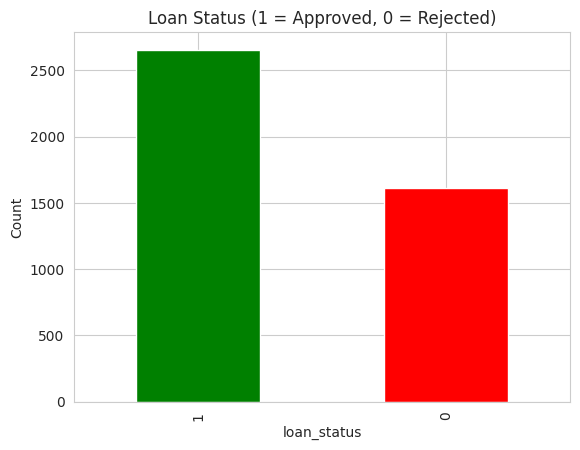

loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64


In [123]:
## Class balance (the most important plot for this task)
import matplotlib.pyplot as plt
import seaborn as sns

df["loan_status"].value_counts().plot(kind="bar", color=["green", "red"])
plt.title("Loan Status (1 = Approved, 0 = Rejected)")
plt.xlabel("loan_status")
plt.ylabel("Count")
plt.show()
print(df["loan_status"].value_counts(normalize=True).round(3))

### Observation: Class Balance
The data is mildly imbalanced (62.2% Approved, 37.8% Rejected). Since accuracy can hide poor performance on the minority class, I will focus on precision, recall and F1-score, and test imbalance techniques like SMOTE.

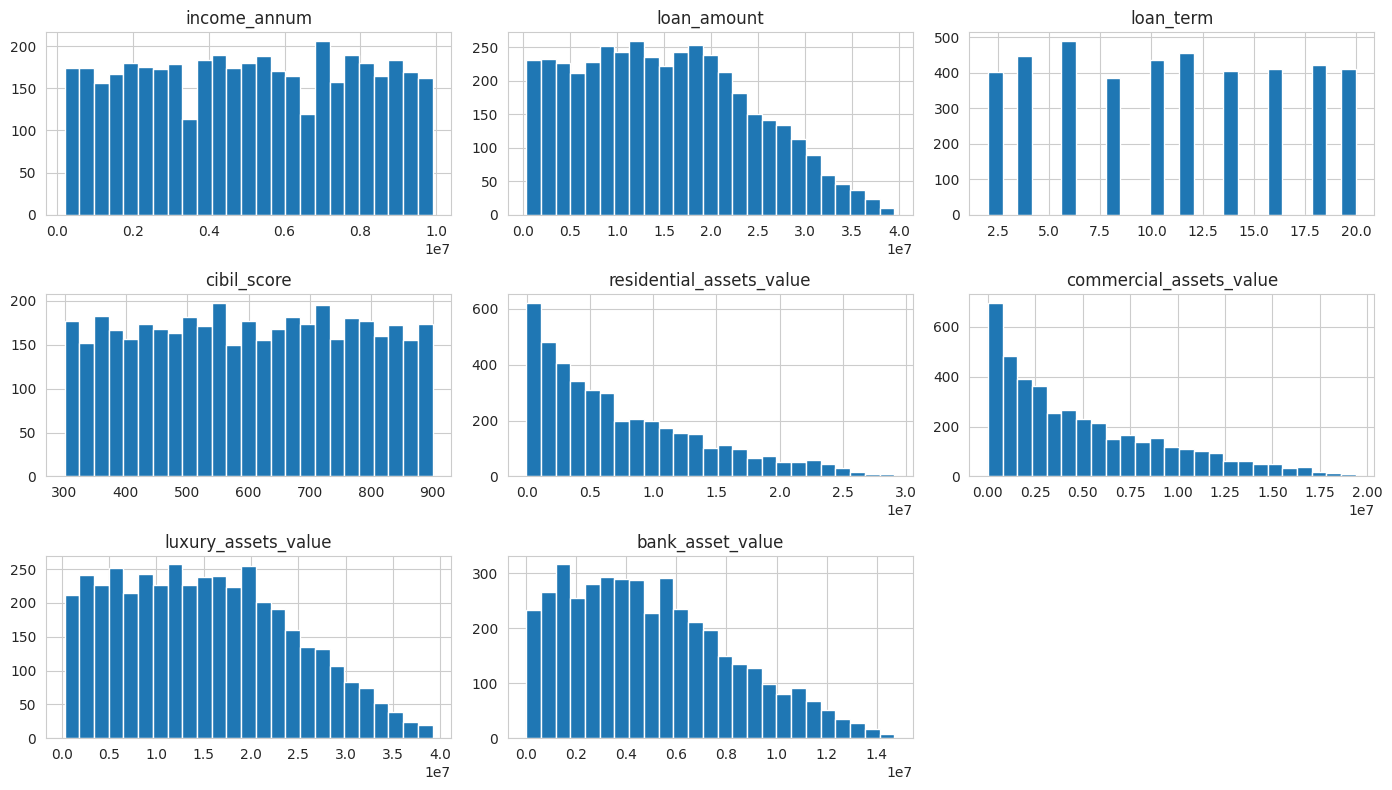

In [124]:
## Distribution of the numeric columns
num_cols = ["income_annum", "loan_amount", "loan_term", "cibil_score",
            "residential_assets_value", "commercial_assets_value",
            "luxury_assets_value", "bank_asset_value"]
df[num_cols].hist(bins=25, figsize=(14, 8))
plt.tight_layout()
plt.show()

### Observation: Distribution of Numerical Features
income_annum and cibil_score are spread fairly evenly. The asset columns are right-skewed (many low values, a few very high). The features are on very different scales, so I will scale them for Logistic Regression.

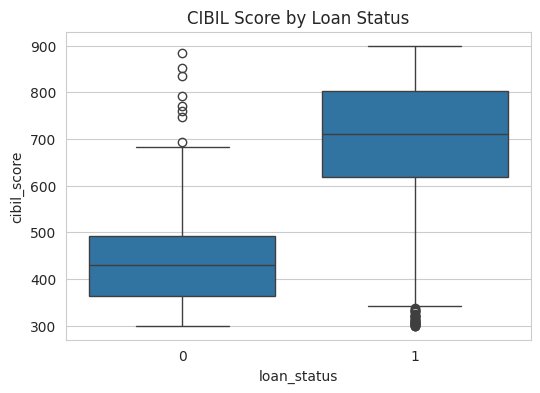

In [125]:
## How the credit score relates to approval
plt.figure(figsize=(6, 4))
sns.boxplot(x="loan_status", y="cibil_score", data=df)
plt.title("CIBIL Score by Loan Status")
plt.show()

### Observation: CIBIL Score
Approved applicants have much higher CIBIL scores (median about 710) than rejected ones (median about 430), and the two boxes barely overlap, so credit score is a strong predictor of approval. A few outliers exist, such as rejected applicants with high scores and approved applicants with very low ones. All values are within the valid 300 to 900 range, so I kept them. These cases also suggest that other factors, not only credit score, affect the decision.

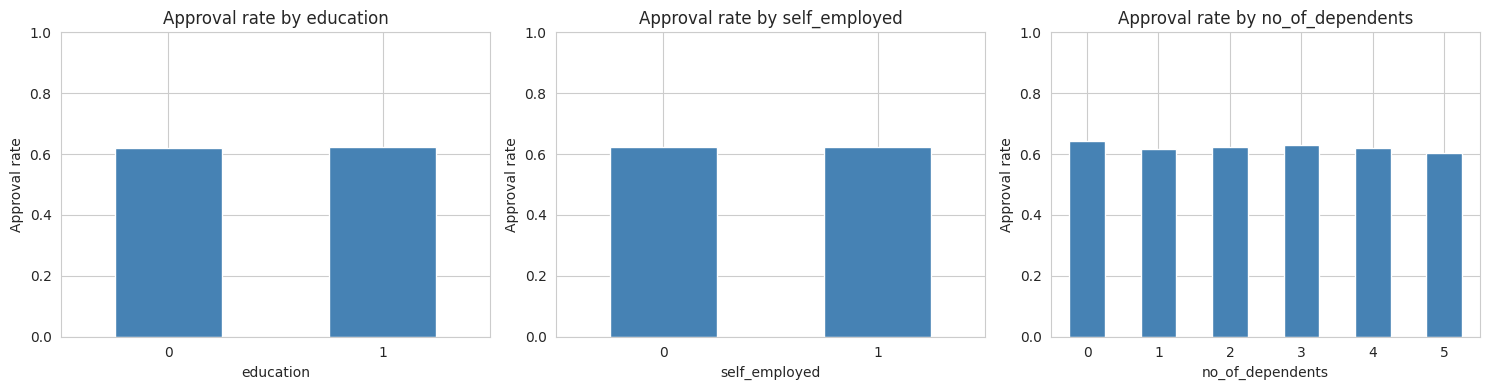

In [126]:
## Approval rate by education, self-employment, and dependents
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["education", "self_employed", "no_of_dependents"]):
    df.groupby(col)["loan_status"].mean().plot(kind="bar", ax=a, color="steelblue")
    a.set_title(f"Approval rate by {col}")
    a.set_ylabel("Approval rate")
    a.set_ylim(0, 1)
    a.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Observation: Education, Self-Employment, Dependents

The approval rate is almost the same (around 62%) across education level, self-employment status, and number of dependents. These features have little effect on approval, unlike credit score.

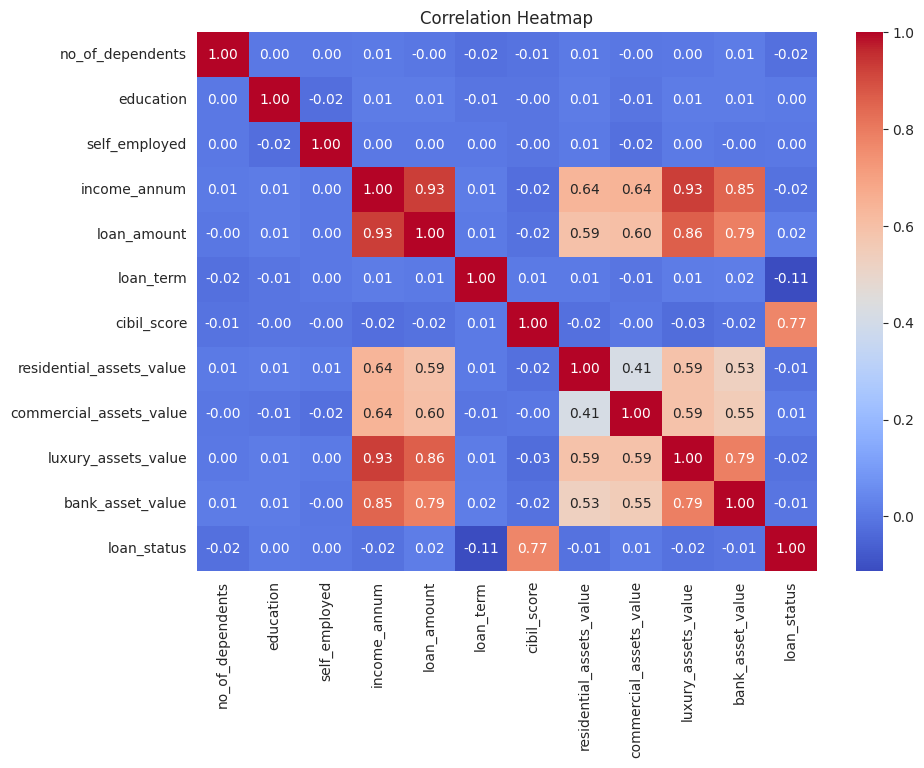

In [127]:
## Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### Observation: Correlation Heatmap

cibil_score has by far the strongest correlation with loan_status (0.77). All other features are close to zero, so they have little linear relationship with approval. Income, loan amount and the asset columns are strongly correlated with each other (for example income and loan amount at 0.93), which is called multicollinearity.

## Train-Test split.

In [128]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["loan_status"])
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [129]:
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(3))

Train: (3415, 11) | Test: (854, 11)
Train class balance:
 loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64
Test class balance:
 loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64
